# Mini-project 1: UBOS District population forecaster

The population figures used here are **illustrative** and in thousands of people. Mbarara and Mbale are additional districts that have been looked at.

In [15]:
from pathlib import Path
import sys
ROOT = Path.cwd()
if not (ROOT / "src").exists() and (ROOT.parent / "src").exists():
    ROOT = ROOT.parent
if not (ROOT / "src").exists():
    raise FileNotFoundError("Open Jupyter in the correct folder")
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
import math
import statistics
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from src.population import (DistrictPopulation, LinearTrend, ExponentialGrowth,
                            FibonacciRatio, error_metrics, bootstrap_interval)

years = np.arange(2015, 2025)
data = {
    "Kampala": [1200,1250,1300,1350,1420,1500,1580,1650,1720,1800],
    "Wakiso": [950,1000,1070,1150,1220,1300,1390,1480,1570,1670],
    "Gulu": [320,330,345,360,375,390,410,430,455,480],
    "Mbarara": [250,258,268,277,288,300,311,324,338,353],
    "Mbale": [210,216,225,234,242,252,263,275,287,301],
}
districts = [DistrictPopulation(name, years, counts) for name, counts in data.items()]
print(districts)

[DistrictPopulation('Kampala', 2015-2024), DistrictPopulation('Wakiso', 2015-2024), DistrictPopulation('Gulu', 2015-2024), DistrictPopulation('Mbarara', 2015-2024), DistrictPopulation('Mbale', 2015-2024)]


## Description and relative growth

`statistics.variance` estimates **sample** variance and divides by n − 1. `np.var()` defaults to **population** variance and divides by n (ddof=0); `np.var(ddof=1)` agrees with `statistics.variance`. Units for variance are (thousand people)². CAGR is relative growth over nine one-year intervals.

In [10]:
rows = []
for d in districts:
    stats = d.describe()
    rows.append({"District": d.name, **stats,
                 "np.mean": np.mean(d.populations), "np.median": np.median(d.populations),
                 "np.var(ddof=0)": np.var(d.populations),
                 "np.var(ddof=1)": np.var(d.populations, ddof=1),
                 "np.std(ddof=1)": np.std(d.populations, ddof=1),
                 "CAGR (%)": 100*d.cagr(),
                 "yearly growth %": np.round(100*d.growth_rates(), 2).tolist()})
summary = pd.DataFrame(rows).set_index("District")
print(summary.round(2).to_string())
print("Fastest relative growth:", summary["CAGR (%)"].idxmax())

            mean  median  variance  std_dev  np.mean  np.median  np.var(ddof=0)  np.var(ddof=1)  np.std(ddof=1)  CAGR (%)                                        yearly growth %
District                                                                                                                                                                        
Kampala   1477.0  1460.0  42601.11   206.40   1477.0     1460.0        38341.00        42601.11          206.40      4.61  [4.17, 4.0, 3.85, 5.19, 5.63, 5.33, 4.43, 4.24, 4.65]
Wakiso    1280.0  1260.0  60066.67   245.09   1280.0     1260.0        54060.00        60066.67          245.09      6.47  [5.26, 7.0, 7.48, 6.09, 6.56, 6.92, 6.47, 6.08, 6.37]
Gulu       389.5   382.5   2885.83    53.72    389.5      382.5         2597.25         2885.83           53.72      4.61  [3.12, 4.55, 4.35, 4.17, 4.0, 5.13, 4.88, 5.81, 5.49]
Mbarara    296.7   294.0   1200.23    34.64    296.7      294.0         1080.21         1200.23           34.64    

## Honest train/test comparison

Fit on 2015–2021 (7 observations). Predict the three unseen 2022–2024 values, then compare MAE, RMSE and MAPE. Proceeds to choose the lowest test MAE; for the final projection, refit it on all ten observations. The Fibonacci ratios are a required comparator, not an endorsed population model.

In [11]:
types = {"linear": LinearTrend, "CAGR": ExponentialGrowth,
         "Fibonacci ratio": FibonacciRatio}
results = {}
selected = {}
for d in districts:
    # Only the first seven years are visible when testing 2022–2024.
    train, test = d.populations[:7], d.populations[7:]
    scores = []
    for name, cls in types.items():
        prediction = cls().fit(train).predict(3)
        scores.append({"model": name, **error_metrics(test, prediction)})
    frame = pd.DataFrame(scores).set_index("model").sort_values("MAE")
    results[d.name] = frame
    selected[d.name] = str(frame.index[0])  # sorted first = lowest test MAE
    print("\n", d.name, "test results, thousands of people:")
    print(frame.round(2).to_string())

future_years = np.arange(2025, 2030)
forecasts, intervals = {}, {}
for d in districts:
    # After selecting a model, use every available year for the final forecast.
    model = types[selected[d.name]]().fit(d.populations)
    forecasts[d.name] = model.predict(5)
    intervals[d.name] = bootstrap_interval(model, d.populations, 5, seed=42, repeats=1200)
plan = []
for d in districts:
    # Convert thousands of people to people BEFORE computing pupils/classrooms.
    growth_people = max(0, (forecasts[d.name][-1]-d.populations[-1])*1000)
    plan.append({"district": d.name, "model": selected[d.name],
                 "2029 forecast (thousands)": forecasts[d.name][-1],
                 "actual sample variance": np.var(d.populations, ddof=1),
                 "forecast sample variance": np.var(forecasts[d.name], ddof=1),
                 "extra classrooms": math.ceil(growth_people*.18/53)})
plan_table = pd.DataFrame(plan).set_index("district")
print("\nFive-year planning table (population values in thousands):")
print(plan_table.round(2).to_string())


 Kampala test results, thousands of people:
                     MAE     RMSE  MAPE (%)
model                                      
CAGR                9.62    10.39      0.55
linear             37.62    38.97      2.17
Fibonacci ratio  3543.33  4025.36    202.00

 Wakiso test results, thousands of people:
                    MAE     RMSE  MAPE (%)
model                                     
CAGR                6.8     8.05      0.42
linear             49.4    52.37      3.09
Fibonacci ratio  3060.0  3479.87    189.87

 Gulu test results, thousands of people:
                    MAE     RMSE  MAPE (%)
model                                     
CAGR               9.44    10.87      2.02
linear            18.57    20.29      4.01
Fibonacci ratio  911.67  1035.64    196.04

 Mbarara test results, thousands of people:
                    MAE    RMSE  MAPE (%)
model                                    
CAGR               3.71    4.17      1.08
linear             8.23    8.93      2.40
Fibona

## 3. Actual values, test period and projections

Shading is an **approximate conditional 95% interval** from 1,200 resamples of historic one-step prediction errors.

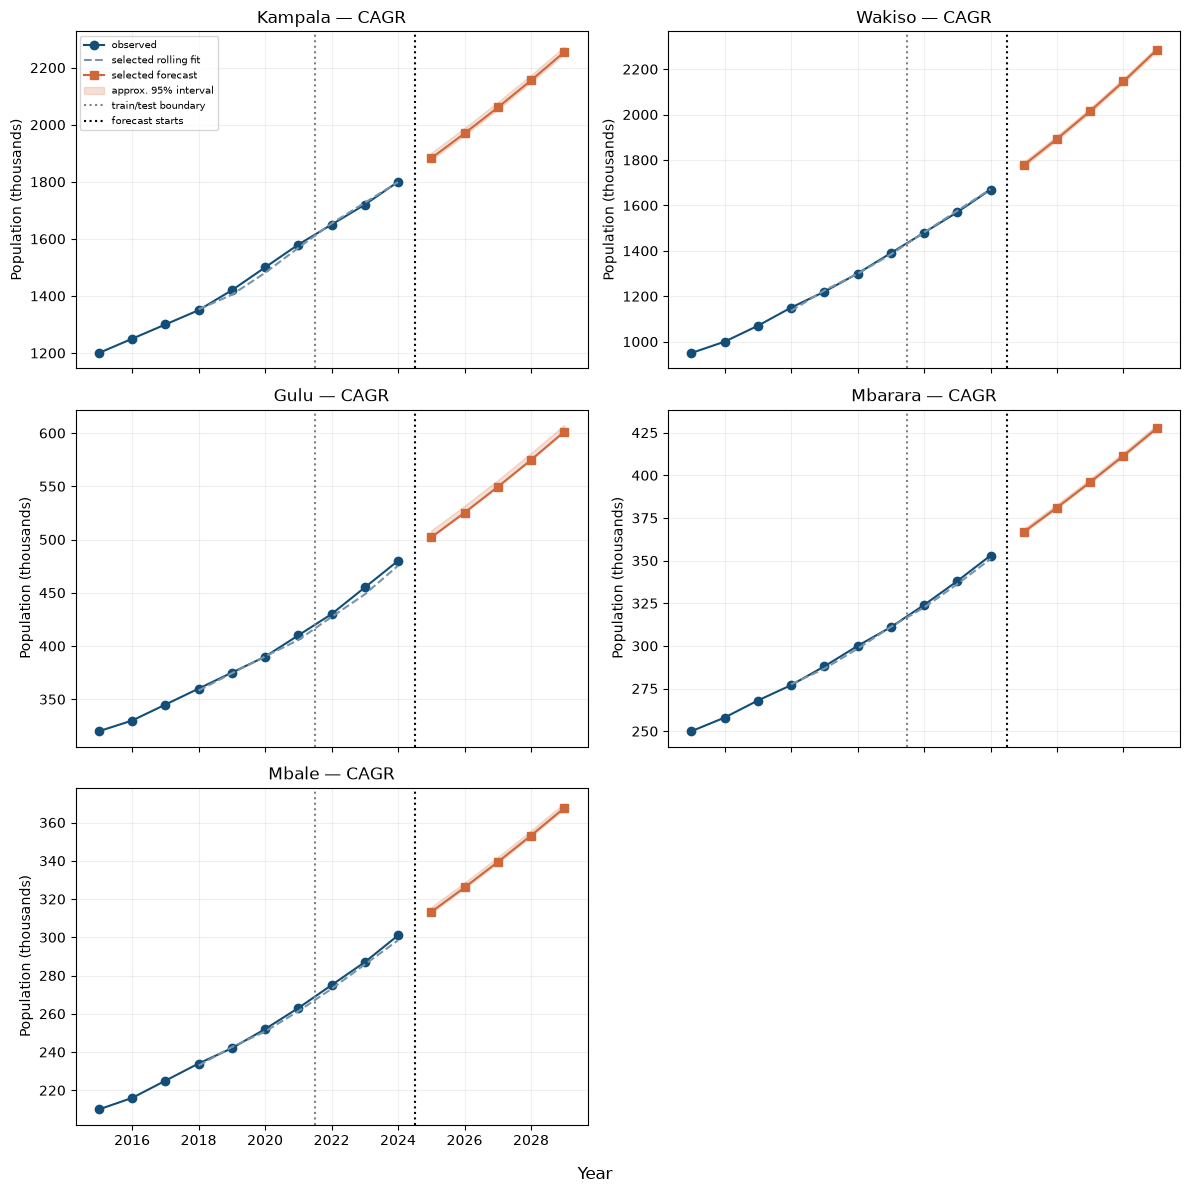

In [12]:
fig, axes = plt.subplots(3, 2, figsize=(12, 12), sharex=True)
for ax, d in zip(axes.flat, districts):
    ax.plot(d.years, d.populations, "o-", label="observed", color="#124e78")
    cls = types[selected[d.name]]
    fitted = [cls().fit(d.populations[:i]).predict(1)[0] for i in range(3, len(d))]
    ax.plot(d.years[3:], fitted, "--", label="selected rolling fit", color="#7794a9")
    ax.plot(future_years, forecasts[d.name], "s-", label="selected forecast", color="#cf6738")
    ax.fill_between(future_years, *intervals[d.name], alpha=.2, color="#cf6738",
                    label="approx. 95% interval")
    ax.axvline(2021.5, color="gray", linestyle=":", label="train/test boundary")
    ax.axvline(2024.5, color="black", linestyle=":", label="forecast starts")
    ax.set_title(f"{d.name} — {selected[d.name]}")
    ax.set_ylabel("Population (thousands)")
    ax.grid(alpha=.2)
axes.flat[-1].axis("off")
axes.flat[0].legend(fontsize=7)
fig.supxlabel("Year")
fig.tight_layout()
plt.show()

## Findings

The five supplied/illustrative series increase throughout the observed decade, but absolute growth and relative growth answer different planning questions. The CAGR table identifies the district with the fastest *percentage* growth, while the 2029 forecasts show where the largest absolute classroom demand could arise. A classroom estimate uses **only additional** pupils between 2024 and 2029: positive population growth × 1,000 × 18% ÷ 53, rounded upwards. It assumes the primary-school share and class size remain fixed and therefore is not an estimate of total existing school need.

Model selection uses 2022–2024 data that were not available to the models fitted through 2021. MAE, RMSE and MAPE describe this short backtest; the chosen method is then refitted on all ten years before producing 2025–2029 values. Forecast variance covers only five projected points and is sensitive to the selected model's slope; comparing it with ten observed points describes dispersion, not forecast accuracy or confidence. Residual bootstrap shading is approximate and cannot capture future migration shocks. The Fibonacci-ratio rule assumes multiplicative factors tending toward about 1.618 annually: a mathematically valid recurrence, but an implausible population-growth mechanism unless a separately justified process follows that recurrence. All figures are illustrative, and real school planning would require UBOS district estimates, boundary checks, and age-specific enrolment data.